In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)
df = online_retail.data.original




In [2]:
print(df.head())
print(df.tail())



  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  
       InvoiceNo StockCode                      Description  Quantity  \
541904    581587     22613      PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899     CHILDREN'S APRON DOLLY GIRL         

In [3]:
# Customer ID debe ser Objet debido a su naturaleza de dato intendificatorio

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [4]:
# Estandarizacion basica de columnas

nombres_originales = df.columns.tolist()
print(f"Nombres originales: {nombres_originales}")


mapeo_nombres = {col: col.strip().lower().replace(' ', '_') for col in nombres_originales}


if any(original != nuevo for original, nuevo in mapeo_nombres.items()):
    for original, nuevo in mapeo_nombres.items():
        if original != nuevo:
            print(f"  '{original}' -> '{nuevo}'")
    df.rename(columns=mapeo_nombres, inplace=True)
else:
    print("Los nombres de columnas ya estaban estandarizados.")

# Mostramos los nombres finales
print(f"\nNombres finales: {df.columns.tolist()}")

Nombres originales: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
  'InvoiceNo' -> 'invoiceno'
  'StockCode' -> 'stockcode'
  'Description' -> 'description'
  'Quantity' -> 'quantity'
  'InvoiceDate' -> 'invoicedate'
  'UnitPrice' -> 'unitprice'
  'CustomerID' -> 'customerid'
  'Country' -> 'country'

Nombres finales: ['invoiceno', 'stockcode', 'description', 'quantity', 'invoicedate', 'unitprice', 'customerid', 'country']


In [5]:
# Empezaremos por los nulos



# 1. Verificar el estado inicial de los nulos
nulos_iniciales = df.isnull().sum()
nulos_iniciales = nulos_iniciales[nulos_iniciales > 0]

print("Columnas con valores nulos ANTES de la imputación:")
for col, n in nulos_iniciales.items():
    print(f"   - '{col}': {n} nulos ({(n/len(df))*100:.2f}%)")

Columnas con valores nulos ANTES de la imputación:
   - 'description': 1454 nulos (0.27%)
   - 'customerid': 135080 nulos (24.93%)


In [6]:
# Despues de hacer verificaciones basicas en los datos, se observan discrepancias en StockCode, Invoiceno y Description, asi que hare un filtro para cada columna que detecte ventas legitimas de ajustes, errores y cualquier otra discrepancia que no sea venta. 

# Filtro para Invoiceno
#Este filtro es pequeño por que se observo que siempre que hay un letra en inoviceno hay quantity negativa sin execpciones.
invoiceno_raro_mask = ~df['invoiceno'].str.isdigit()                                                                      

invoiceno_raro = df[invoiceno_raro_mask]


In [7]:
# Filtro para Stockcode

# Patrón para códigos legítimos (números + 1 letra al final)
legit_pattern = r'^\d+[A-Za-z]$'

# Patrón para códigos anómalos (solo letras)
anomaly_pattern = r'^[A-Za-z]+$'

# Máscara para detectar códigos anómalos
stockcode_anomalo_mask = (
    ~df['stockcode'].str.isdigit() &  
    ~df['stockcode'].str.contains(legit_pattern, na=False)  
)

# O alternativamente, detectar directamente solo letras
stockcode_anomalo_mask = df['stockcode'].str.contains(r'^[A-Za-z]+$', na=False)

# Filtrar
stockcode_anomalo = df[stockcode_anomalo_mask]
stockcode_anomalo['stockcode'].unique()

stockcode_unitprice0 = stockcode_anomalo[stockcode_anomalo['unitprice'] == 0]

stockcode_anomalo['stockcode'].unique()


<StringArray>
[     'POST',         'D',       'DOT',         'M',         'S', 'AMAZONFEE',
         'm',  'DCGSSBOY', 'DCGSSGIRL',      'PADS',         'B',      'CRUK']
Length: 12, dtype: str

In [86]:
# Filtro para Description

# Aqui le pedi a la IA que me ayudara a fortalecer el filtro de las anomalias en descripcion para detectar ajustes administrativos, errores de captura y perdidas/daños con el output de unique() para separar por palabras los tipos de patrones. 
# Mejorar el filtro de Description para descartar datos legitimos que incluyen 'cm' , 'x', 'g' que pertenecen a medidas de los productos *

import re

# Patrón para detectar PALABRAS COMPLETAS en minúsculas (no solo contener la palabra)
lowercase_words_pattern = r'\b[a-z]+\b'

# Patrón para detectar anomalías con signos
suspicious_signs = r'[?*!]'

# Palabras que SOLO son sospechosas si están en minúsculas
suspicious_lowercase = r'\b(?:damage|broken|cracked|crushed|rusty|mouldy|CARRIAGE|Bank|Charges|wet|missing|lost|check|found|samples|adjust|credit|return|reverse|wrong|incorrect|barcode|code|mix|faulty|throw|sold|set)\b'

# Patrón para excluir productos legítimos (los que tienen palabras en MAYÚSCULAS)
legit_pattern = r'\bSET\b|\bBAG\b|\bBOX\b|\bCARD\b|\bMUG\b|\bTEA\b|\bPLATE\b|\bCUP\b|\bBOWL\b|\bTIN\b|\bCOOKIE\b|\bCANDLE\b|\bLIGHT\b|\bORNAMENT\b|\bDECORATION\b|\bGIFT\b|\bPACK\b|\bJAR\b|\bNECKLACE\b|\bEARRINGS\b|\bBRACELET\b|\bHANGERS\b|\bTHROW\b|\bDOORSTOP\b|\bMARKER\b'


# Patrón para detectar ventas especiales (amazon/dotcom + sold/sales)
sales_pattern = r'(amazon|carriage|dotcom).*(sold|sales|set)'

# Máscara final con exclusión de ventas
mask2 = (
    df['description'].str.contains(suspicious_lowercase, na=False) &
    ~df['description'].str.contains(legit_pattern, case=False, na=False) &
    ~df['description'].str.contains(r'\d+\s?[xX]\s?\d+\s?[cC][mM]|\d+\s?[gG]\b|\d+\s?[kK][gG]\b|\d+\s?[cC][mM]\b', na=False) &
    # EXCLUIR ventas especiales
    ~df['description'].str.contains(sales_pattern, case=False, na=False) &
    # EXCLUIR "sold" cuando es venta (pero mantener cuando es error)
    ~df['description'].str.contains(r'\bsold\s+as\s+set\b|\bsold\s+in\s+set\b', case=False, na=False) &
    ~df['description'].str.contains(r'\bsales\b', case=False, na=False)
)
anomalias2 = df[mask2]

#anomalias2
anomalias2['description'].unique()


/tmp/ipykernel_14913/4210256639.py:30: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~df['description'].str.contains(sales_pattern, case=False, na=False) &


<StringArray>
[                           'CARRIAGE',                        'Bank Charges',
                               'check',                              'faulty',
          'reverse 21/5/10 adjustment',        'BLACK BAROQUE CARRIAGE CLOCK',
                'mouldy, thrown away.',                               'found',
                        'label mix up',                     'samples/damages',
                'wrongly sold as sets',                   'wrongly sold sets',
                     '? sold as sets?',                      '?sold as sets?',
                              'broken',               'wrong barcode (22467)',
        'wrongly sold (22719) barcode',                       'wrong barcode',
                     'barcode problem',                               '?lost',
                             'cracked',                       'sold as 22467',
 'did  a credit  and did not tick ret',                         'wrong code?',
                          'wrong code'

In [9]:
# Siempre que invoiceno tiene letras en sus datos quantity siempre tiene valores negativos, teniendo como maximo 1.0 
# Los otros dos grupos tienen rangos positivos como negativos en sus columnas numericas 

# Este estudio rapido me ayuda a entender como se comportan las columnas anomalas, aunque no aporten nada ya registre la distribucuion de los datos con discrepancias. 


columnas_numericas_stockcode = stockcode_anomalo.select_dtypes(include= np.number).columns
columnas_numericas_description = anomalias2.select_dtypes(include= np.number).columns
columnas_numericas_invoiceno = invoiceno_raro.select_dtypes(include= np.number).columns

for columna in columnas_numericas_stockcode:
    print('stockcode raro')
    print(stockcode_anomalo[columna].describe())

for columna in columnas_numericas_description:
    print('anomalias_description')
    print(anomalias2[columna].describe())

for columna in columnas_numericas_invoiceno:
    print('invoiceno raro')
    print(invoiceno_raro[columna].describe())




stockcode raro
count    2759.000000
mean        3.634288
std        67.822792
min     -1350.000000
25%         1.000000
50%         1.000000
75%         2.000000
max      1600.000000
Name: quantity, dtype: float64
stockcode raro
count     2759.000000
mean       261.630019
std       1329.514211
min     -11062.060000
25%         16.925000
50%         18.000000
75%        161.120000
max      38970.000000
Name: unitprice, dtype: float64
stockcode raro
count     1774.000000
mean     13636.350056
std       1684.297294
min      12348.000000
25%      12540.250000
50%      12693.000000
75%      14527.000000
max      18283.000000
Name: customerid, dtype: float64
anomalias_description
count     541.000000
mean      -72.826248
std       317.766621
min     -3000.000000
25%       -30.000000
50%         1.000000
75%         1.000000
max      1300.000000
Name: quantity, dtype: float64
anomalias_description
count     541.000000
mean       28.358930
std        87.343265
min         0.000000
25%         

In [10]:
# refinado la máscara de stockcode_raro para distinguir entre códigos con letras legítimas (85123A) y códigos anómalos (POST, DOT).*
# refinado la máscara de description_raro para separar productos legítimos (BAG 500g) de transacciones administrativas (damaged). *

# Cree un df aislado con los filtros anomalos para poder estudiarlos por separado
# Justificacion; Estre Proyecto tiene como objetivo estudiar y predecir el comportamiento del consumidor, cualquier registro sin id, con error de captura, maniobra operativa o movimiento administrativo no debe estar en la muestra para crear el modelo por que no aportaria nada.

df_anomalias_mask = mask2 | stockcode_anomalo_mask | invoiceno_raro_mask | pd.isnull(df['customerid'])

df_anomalias =df[df_anomalias_mask]

    


In [11]:
# Hice exactamente el mismo filtro pero invertido para un df con los datos saludables y utiles para el modelo 

df_saludable_mask = ~stockcode_anomalo_mask & ~mask2 & ~pd.isnull(df['customerid']) & ~invoiceno_raro_mask
df_saludable = df[df_saludable_mask]


# Con esta ultima verificacion termino de asegurarme que no hayan nulos legitimos
pd.isnull(df_saludable).sum()

# Los nulos disfrazados ya fueron purgados, y no hubo necesidad de imputar datos


invoiceno      0
stockcode      0
description    0
quantity       0
invoicedate    0
unitprice      0
customerid     0
country        0
dtype: int64

In [12]:
# Verificacion del todal de df original
len(df_saludable) + len(df_anomalias)


541909

In [13]:
# Pasamos a la fase de duplicados 

# Haciendo algunas pruebas, por la naturaleza de inviceno di por hecho que solo necesitaba elegir esa columna y cutomerid para detectar duplicados exactos, despues de algunas observaciones hice mas especifica la busqueda de duplicados pues dos columnas no bastaron,
# Hay duplicados en la misma factura pero con diferentes quantity, no los tomaremos en cuenta como duplicados exactos por falta de evidencia, asi que solo tomare en cuenta duplicados exactos 

duplicados = df_saludable[df_saludable.duplicated(subset=['invoiceno','stockcode','description','quantity','invoicedate','unitprice','customerid','country'],keep=False)]
duplicados.nunique()

# existen 9995 duplicados exactos 

invoiceno      1883
stockcode      1690
description    1716
quantity         25
invoicedate    1864
unitprice        75
customerid      950
country          12
dtype: int64

In [14]:
# Haciendo pruebas con el codigo a continuacion pero con index diferente, me doy cuenta que a veces hay un segundo cobro en la misma factura pero quantity diferente del mismo producto, o a veces con el mismo quantity

factura_ejemplo_invoiceno = duplicados['invoiceno'].iloc[489]
factura_ejemplo_stockcode = duplicados['stockcode'].iloc[489]

df_saludable[(df_saludable['invoiceno'] == factura_ejemplo_invoiceno) & (df_saludable['stockcode'] == factura_ejemplo_stockcode)]

,invoiceno,stockcode,description,quantity,invoicedate,unitprice,customerid,country
13996,537441,22114,HOT WATER BOTTLE TEA AND SYMPATHY,1,12/6/2010 17:26,3.95,13564.0,United Kingdom
14003,537441,22114,HOT WATER BOTTLE TEA AND SYMPATHY,1,12/6/2010 17:26,3.95,13564.0,United Kingdom


In [15]:
# Genero una mascara para filtrar todos los duplicados con el criterio ya verificado y de nuevo genero un df sin tocar el original y el que conserva duplicados para tener documentacion consistente



duplicados_mask = df_saludable.duplicated(subset= ['invoiceno','stockcode','description','quantity','invoicedate','unitprice','customerid','country'],keep=False)
df_sano = df_saludable[~duplicados_mask]

# Este nuevo conjunto conserva 386520 filas, un 71% del df original


In [16]:
# Pasamos a outliers, hice pruebas, en quantity, unitprice e invoicedate y solo en quantity aparecieron numeros sospechosos
# El numero mas alto tiene un quantity de 80995, despues hice una exploracion escalonada de 80000 hacia abajo, el numero maximo en quantity pasa de ser 'comun' a casos extraordinarios a partir de cantidades mayores a 2000

df_sano[df_sano['quantity'] > 1500].count()


invoiceno      40
stockcode      40
description    40
quantity       40
invoicedate    40
unitprice      40
customerid     40
country        40
dtype: int64

In [17]:
# El primer problema que tuve con los outliers es que no se si todos los clientes ahi estan por errores de captura en quantity o si son legitimos
# Primero voy a definir en proporcion a este conjunto de datos a que se le puede llamar mayorista
# Tengo planeado hacer segmentacion de clientes por volumen de compra, primero observando cuantas compras con mas de 100 unidades hay, si bien aun no estoy en fase FE esto me ayuda a entender los outliers y a preparar el terreno para las nuevas variables 


# Con esta verificacion me doy cuenta que tan habituales son, el numero de clientes unicos son 740, el numero se redujo a casi una sexta parte del total

mayoristas = df_sano[df_sano['quantity'] >= 100]
mayoristas['customerid'].nunique()


740

In [18]:
# Ahora investigare cuantas compras mayoristas por usuarios es lo normal en este conjunto para entender que podria considerarse casos extraordinarios

conteo_matyoristas = mayoristas['customerid'].value_counts()
conteo_matyoristas.value_counts()


# Encontre un cliente con 789 compras, tengo que investigarlo para saber si es legitimo, de momento no se si deba seguir en el conjunto ya que es un dato muy raro y puede generar asimetria en la distribucion por el volumen de compras que tiene
# Tambien hay otro que compro 12,000 unidades de un producto que al parecer era gratis, ambos los elimino, uno por que es una cantidad que no tiene sentido para un negocio minorista, y otro por que es un claro caso extraoordinario que no refleja un comportamiento habitual
# Otro mas aparecio que tiene 74,000 compras de Jarrones de Ceramica, suena muy sospechoso y ademas el numeor no es redondo, parece mas un error de dedo, tambien lo eliminare por estas mismas señales. 


# Ambos los detecte con el codigo a continuacion sustituyendo el id
# mayorista_sospechoso = df_sano[df_sano['customerid']== 14646]
# mayorista_sospechoso['quantity'].unique()

count
1      362
2      123
3       44
5       38
4       36
6       18
7       10
10       9
8        8
12       7
11       6
18       5
15       5
14       5
17       4
9        4
30       3
26       3
16       3
13       3
160      2
31       2
24       2
22       2
21       2
789      1
296      1
260      1
249      1
248      1
174      1
155      1
142      1
115      1
109      1
103      1
86       1
80       1
77       1
74       1
73       1
69       1
67       1
59       1
55       1
53       1
47       1
44       1
43       1
41       1
40       1
39       1
37       1
34       1
33       1
27       1
25       1
23       1
19       1
Name: count, dtype: int64

In [19]:
# Ahora hare los mismo pero para facturas con volumenes altos de compras, asi sabre si hay dos tipos de clientes mayoristas, unos con compras aisladas de un solo producto con quantity elevado y otro de compras en conjunto de mas de 100 unidades entre varios productos
# Aparecieron 12236 facturas con compras que superan 100 unidades en quantity en total
# No voy a nombrarlos todavia, para no introducir sesgo 
# Dejare que K-Means escoga los grupos naturales de compradores, pero me aseguro de documentar estos descubrimientos para usarlos en a fase FE


agrupacion_facturas = df_sano.groupby('invoiceno')['quantity'].sum()
(agrupacion_facturas >= 100).sum()

np.int64(12235)

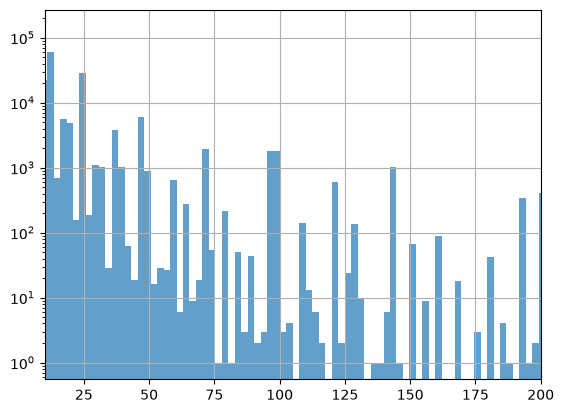

In [20]:

# Ahora toca ver la distribucion del conjunto, planeo winsorizar los numeros 'redondos' de los mayoristas que pasan de 2000 unidades
# En funcion de la distribucion tratare de entender cual es el mejor percentil para winsorizar 


# Hay un claro sesgo hacia la derecha
# Es multimodal en multiplos de 12, parece que los clientes se sienten mas comodos comprando en docenas por naturaleza pues hay picos y caidas alrededor de eso numeros
# Me encontre con menos outliers de los que esperaba 


import matplotlib.pyplot as plt

temporal_quantity = df_sano[df_sano['quantity']< 1500]


temporal_quantity['quantity'].hist(bins=600, alpha= 0.7)
plt.xlim(10,200)
plt.yscale('log')

In [21]:
# Ahora directamente hago una investigacion escalonada de percentil 95 a 99.99 en quantity para entender cuales son los limites de los casos extraordinarios en quantity
# Percentil 95 = 40 
# Percentil 99 = 126 
# Percentil 99.5 = 200
# Percentil 99.9 = 508
# Percentil 99.99 = 1,524

df_sano['quantity'].quantile(0.9999)

np.float64(1524.2199999999139)

In [22]:
# Escogi el percentil 99.99% dado que en esa zona parece ser el limite antes de disparar la distribucion
# Sustituire la variable por la variable winsorizada despues de hacer una copia protocolaria

df_sano_w = df_sano.copy()
percentil_maximo = df_sano['quantity'].quantile(0.9999)

df_sano_w['quantity'] = df_sano_w['quantity'].clip(upper= percentil_maximo)

In [23]:
# Ahora eliminare las tres compras de los outliers que superan los 10,000 unidades, el cliente que aprovecho un error del negocio, el cliente que compro 74,000 jarrones y el cleinte de mas de 80,000 unidades

id_out = ['541431', '578841', '581483']
df_sano_w = df_sano_w[~df_sano_w['invoiceno'].isin(id_out)]

In [24]:
# Pasamos a formatos y cosistencia

# Primero hago una revision del formato original en fecha para ver cuales son los primeros caracteres y determinar cual es orden correcto en que debo asignar la fecha
df['invoicedate'].astype(str).str[:2].value_counts()

# Al parecer no hace falta agregar condiciones extra, el formato original no necesita dayfirst en datetime, el codigo anterior me muestra una lista de 1 a 12
df_sano_w['invoicedate'] = pd.to_datetime(df_sano_w['invoicedate'])


In [25]:
# Resivsando Country y sus formatos me doy cuanta que hay dos categorias a tratar, Unspecified y European Community, ambas no suponen un problema mientras customerid no falte, por protocolo este matiz deberia informarse a skateholders o responsables antes de continuar.

# Decisión: 'Unspecified' se mantiene como categoría propia.
# Justificación: hay customerid válido, información útil en otras columnas.
# Implicación: se tratará como grupo aparte en EDA y modelado por país.

df_sano_w['country'].unique()

<StringArray>
[      'United Kingdom',               'France',            'Australia',
          'Netherlands',              'Germany',               'Norway',
                 'EIRE',          'Switzerland',                'Spain',
               'Poland',             'Portugal',                'Italy',
              'Belgium',            'Lithuania',                'Japan',
              'Iceland',      'Channel Islands',              'Denmark',
               'Cyprus',               'Sweden',              'Finland',
              'Austria',               'Greece',            'Singapore',
              'Lebanon', 'United Arab Emirates',               'Israel',
         'Saudi Arabia',       'Czech Republic',               'Canada',
          'Unspecified',               'Brazil',                  'USA',
   'European Community',              'Bahrain',                'Malta',
                  'RSA']
Length: 37, dtype: str

In [26]:
# Pasamos a description, como ya habia revisado antes la columna con exploracion basica, se que hay mucha dimensionalidad en los productos, revisare stockcode a ver si encuentro pistas que me ayuden a categorizar rapidamente grupos grandes de productos.
# Hay unos 20 pares de codigos diferentes, no me parece rara, sospecho que deben clasificar categorias completas de prodcutos en cada primer par de digitos en stockcode

#df_sano_w['stockcode'].astype(str).str[:2].value_counts().head(20)

In [27]:
# Hice una exploracion de 3, 4 y 5 digitos y la cardinalidad de la columa se disparó, no me conviene agrupar por digitos en stockcode para nombrar las cateogrias de description. 
# Probe extrayendo solo la ultima palabra de cada descripcion en cada subgrupo, pero no habian resultados consistentes, las palabras variaban mucho y las categorias no tenian coherencia respecto a departamentos de mercancia del mismo tipo

#df_sano_w.groupby(df_sano_w['stockcode'].astype(str).str[:3])['description'].unique() ##########################
#df_sano_w[df_sano_w['stockcode'].astype(str).str[:5]== '85123']['description'].apply(lambda x: x.split()[-1]).count() ##########################

In [28]:
# Usare el camino largo, hare listas de palabras para categorias generales apuntando a un 70% de precision en cada categoria, esto por que el metodo perse suele tener parametros ambiguos de precision, es el camino mas eficiente para lo que se pretende en comportmaiento de consumidor aunque me tome un poco mas de tiempo. 

# No usare un loop por que puede ser restrictivo para procesar 380K filas de datos
# Optare por vectorizar a traves de mascaras para facilitar el trabajo
# Diseñare un filtro que decida categoria por la primera categoria con la que haga match cada fila, con un contador extra que detecte si hubo empate o no
# Asi podré medir la precision de la mascara y saber si hacen falta ajustes
# Este contratiempo funge mas como descubrimiento como recomendacion para el negocio, "el registro de productos es ambiguo y degrada la capacidad de análisis", se documenta.



In [29]:
# Hubieron algunos contratiempos, hay muchas palabras ambiguas dentro del conjunto, nombres de colecciones que se asemejan a personajes de fantasia que estab incluyendo en juguetes, estoy considerando la opcion de priorizar precision pero poco mas de las filas por tiempo y esfuerzo en esta parte del set, la naturaleza de los datos es restrictiva en este aspecto
# Hare una busqueda retroactiva de las palabras mas comunes y vere a que categoria pertenecen en funcion de ese contador 
# Para esto use a la IA para que clasificara palabras por contexto y generara biagramas, asi tendre palabras con mas peso y menos ambiguedad que refuercen la clasificacion, tambien use Counter para hacer el analisis mas rapido

categorias = {
    'cocina': [
        'cutlery', 'baking', 'recipe', 'jam', 'making', 'jug', 'enamel',
        'milk', 'egg', 'kitchen', 'napkins', 'chocolate', 'apron', 'scales',
        'cakestand', 'teapot', 'teacup', 'saucer', 'cookie', 'snack',
        'chilli', 'jelly', 'warmer', 'tin', 'tins', 'bottle', 'bowl', 'bowls',
        'plate', 'cup', 'mug', 'tea', 'cake', 'jar',
        'recipe box', 'jam making', 'jam making set', 'measuring spoons',
        'egg holder', 'popcorn holder', 'food cover', 'pantry',
        'teaspoon', 'teaspoons', 'chopping', 'board','t-lights', 'beaker', 'butter', 'dish', 'bread', 'diner',
        'can', 'tray', 'herb','oven', 'crackers', 'cocktail', 'ice', 'coaster','sugar', 'pears', 'straws', 'frying', 'pan', 'toast', 'sponge',
        'biscuit', 'cutters', 'salt', 'pepper', 'fruit', 'coffee',
        'place', 'settings', 'coasters', 'chocolatecandle','breakfast', 'placemat', 'placemats', 'tablecloth', 'apples',
        'pudding', 'spoon', 'cloche', 'flask', 'trays', 'tealight',
        'candlepot'
    ],

    'juguetes': [
        'toy', 'game', 'puzzle', 'doll', 'dolly', 'kite', 'playhouse',
        'building', 'dominoes', 'glider', 'gliders', 'harmonica', 'gumball',
        'craft', 'snap', 'cards', 'play', 'fun', 'kids', 'children',
        'snap cards', 'playing cards', 'jigsaw', 'blocks', 'alphabet blocks',
        'jigsaw blocks', 'snakes', 'ladders', 'rounders', 'spaceboy','balloons', 'treasure','matches', 'spinning', 'tops', 'mice', 'block', 'paint',
        'advent', 'nancy', 'knitting','bingo', 'skittles', 'ball', 'balloon', 'teddy', 'bunny',
        'naughts', 'crosses', 'top', 'modelling', 'clay', 'windmill',
        'friends', 'charlie+lola','mobile', 'circus', 'parade', 'helicopter', 'sandcastle',
        'dinosaur', 'snake', 'scottie', 'army', 'camouflage',
        'flying', 'grow', 'blossom', 'enchanted', 'forest'
    ],

    'papeleria': [
        'cards', 'ribbon', 'ribbons', 'gift', 'felt', 'notebook', 'pen',
        'pencil', 'pencils', 'sticker', 'wrap', 'paper', 'envelope',
        'card', 'label', 'tag', 'journal', 'diary', 'album', 'note', 'notes',
        'ribbon reel', 'reel', 'message cards', 'envelopes', 'sewing',
        'sewing kit', 'stencil', 'felt craft', 'tissues','pad', 'marker', 'ruler', 'stamp', 'book', 'tissue','stationery', 'stickers', 'tape', 'pens', 'calendar',
        'invites', 'colouring', 'sketchbook', 'exercise', 'books',
        'letters', 'envelopes','crayons', 'notebooks', 'writing', 'postcard', 'parcel',
        'memoboard', 'clips', 'glitter', 'acrylic', 'print',
        'badges', 'dispenser', 'secret','erasers', 'scissor', 'letter', 'font', 'transfer', 'tattoos',
        'button', 'paperweight', 'blackboard', 'feltcraft', 'fabric',
        'embossed'
    ],

    'accesorios_personales': [
        'lunch', 'necklace', 'bracelet', 'bag', 'umbrella', 'scarf', 'ring',
        'earring', 'hat', 'purse', 'wallet', 'keyring', 'badge', 'brooch',
        'coin', 'glasses', 'sunglasses', 'watch', 'hair', 'clip', 'comb',
        'lunch box', 'jumbo shopper', 'shopper', 'passport', 'passport cover',
        'cushion', 'cushion cover','parasol', 'cases','babushka', 'money', 'key', 'fob', 'jewellery', 'charms',
        'gloves', 'glove', 'lip', 'gloss', 'parasols', 'fan', 'cigar','hairband', 'backpack', 'bags', 'piggy', 'bank', 'girl',
        'personal', 'soap', 'bath', 'repair','poncho', 'washbag', 'sleeping', 'earrings', 'keyrings',
        'hairbands', 'slipper', 'shoes', 'bib', 'baby', 'childs',
        'boy', 'flannel', 'led', 'torch'
    ],

    'hogar': [
        
        'decoration', 'hanging', 'frame', 'garden', 'star', 'trinket',
        'hook', 'candles', 'candle', 'photo', 'slate', 'zinc', 'wall',
        'door', 'mirror', 'clock', 'light', 'doormat', 'bunting', 'drawer',
        'ornament', 'antique', 'chalkboard', 'magnets', 'sewing',
        'metal sign', 'sign', 'wicker', 'heart', 'photo frame', 'cornice',
        'lantern', 'planter', 'cabinet', 'tidy', 'hanger', 'fridge magnets',
        'trinket box', 'trinket pot', 'pot', 'thermometer', 'christmas',
        'christmas decoration', 'christmas tree', 'birdhouse', 'wreath',
        'candleholder', 'photo cube', 'photo clip', 'wall art', 'wall tidy','garland', 'bin', 'mat', 'rack', 'pegs', 'parasol',
        'kneeling', 'keep calm','doorstop', 'container', 'boxes', 'chest', 'storage',
        'decorations', 'lights', 'magnetic', 'washing', 'rope','basket', 'windmill', 'chalk', 'horse', 'soldier', 'stool',
        'plant', 'bath', 'sponge', 'disco', 'birdcage', 'fairy',
        'doilies', 'incense', 'cottage', 'hammock', 'memoboard',
        'rocking', 'toadstools', 'bird', 'pegs', 'peg', 'doorsign',
        'butterfly', 'bicycle', 'amelie','shelf', 'lamp', 'hooks', 'crates', 'market', 'decorative',
        'blackboard', 'spade', 'tile', 'curtain', 'cosy', 'goose',
        'feather', 'dragonfly', 'ducks', 'birds', 'rabbit', 'bunnies',
        'cat', 'dogs', 'number', 'letter', 'jean-paul', 'beach', 'flags'
    ],
}

df_sano_w['categoria'] = None
df_sano_w['empate'] = None


# Este bloque es sencillo,  uso \b para aislar las palabras con mayor precision y evitar que que la clasificacion haga match parcial
# Tuve que simplificarlo de esta manera por que habia encontrado un bug que estaba aglomerando empates por la cantidad de mascaras que genere

for nombre, palabras in categorias.items():

    patron = '|'.join(r'\b' + p + r'\b' for p in palabras)
    mask = df_sano_w['description'].str.lower().str.contains(patron, na=False)

    df_sano_w.loc[mask & df_sano_w['categoria'].isna(), 'categoria'] = nombre

    cond = mask & df_sano_w['categoria'].notna() & (df_sano_w['categoria'] != nombre)
    
    prev = df_sano_w.loc[cond, 'empate']
    df_sano_w.loc[cond, 'empate'] = prev.apply(lambda x: nombre if pd.isna(x) else f"{x} {nombre}")

    

In [30]:
# Dentro de los productos de la tienda observé bastante actividad de productos navideños, explorare la idea de hacer una columna binaria que registre cuando un prodcuto es de navidad.
# Esto, con la finalidad de crear dos columnas, una que registre funcionalidad del producto y otra estacionalidad de navidad, asi puedo conservar informacion valiosa de los productos navideños. 

#df_sano_w[df_sano_w['categoria'].isna()]['description'].str.split().str[:].value_counts().head(50)

In [31]:
# Este es un codigo de orden de prioridad, sirve para darle prioridad a palabras especificas por encima de palabras genericas que son las que estan en las ultimas categorias de la lista
# Con esto la columna de empate quedo vacia, se creó con intencion de medir la precision de las clasificacion y usarla como retroalimentacion para pulir el diccionario

prioridad = ['accesorios_personales', 'papeleria', 'cocina', 'juguetes', 'hogar']

def resolver_empate(row):
    if pd.isna(row['empate']):
        return row['categoria']
    cats = row['empate'].split()
    for p in prioridad:
        if p in cats:
            return p
    return row['categoria']

mask_empate_real = df_sano_w['empate'].notna() & (df_sano_w['empate'].str.split().str.len() > 1)
df_sano_w.loc[mask_empate_real, 'categoria'] = df_sano_w.loc[mask_empate_real].apply(resolver_empate, axis=1)
df_sano_w.loc[mask_empate_real, 'empate'] = None



# Contador de categorias y empates
mask_empate_1 = df_sano_w['empate'].notna() & (df_sano_w['empate'].str.split().str.len() == 1)

df_sano_w.loc[mask_empate_1, 'categoria'] = df_sano_w.loc[mask_empate_1, 'empate'].str.split().str[0]
df_sano_w.loc[mask_empate_1, 'empate'] = None


print(df_sano_w['categoria'].value_counts())
print("Sin clasificar:", df_sano_w['categoria'].isna().sum())
print("Empates restantes:")
print(df_sano_w['empate'].value_counts().head(10))

categoria
hogar                    170728
accesorios_personales     73941
cocina                    64796
papeleria                 51879
juguetes                  21022
Name: count, dtype: int64
Sin clasificar: 3944
Empates restantes:
Series([], Name: count, dtype: int64)


In [32]:
# Este es el bloque que alimenta el diccionario de forma retroactiva, paso las palabras con algunos ejemplos de oraciones completas dentro del set a la IA y las separo por contexto

from collections import Counter

no_clas = df_sano_w[df_sano_w['categoria'].isna()]['description'].str.lower()

counter = Counter()
for desc in no_clas.dropna():
    for w in desc.split():
        counter[w] += 1

palabras_dicc = set()
for lista in categorias.values():
    for p in lista:
        palabras_dicc.update(p.split())

for w, c in counter.most_common(150):
    if w not in palabras_dicc:
        print(f"{w:25s} {c}")

assorted                  400
of                        374
small                     324
flower                    298
rose                      290
pink                      284
glass                     269
blue                      219
6                         208
colour                    176
painted                   168
funky                     149
union                     147
white                     145
2                         145
vintage                   139
ceramic                   134
magnet                    132
hearts                    118
english                   117
large                     114
design                    110
knickerbockerglory        110
"leis"                    103
jack                      103
black                     100
party                     93
cones                     93
boom                      92
speaker                   92
spirit                    92
level                     92
creepy                    91
crawlies         

In [33]:
# La fase de clasificacion acaba con solo 3944 filas sin calsificar, para el tamaño del conjunto es aceptable.
# Dejamos la clasificacion de productos en 382366 filas clasificadas, mas del 95% del total. 

# Pasamos a separadores inconsistentes y corregir formatos numéricos y convertir a tipo numérico
# customerid aun tenia datos faltantes, al ser columna identificativa se descarta imputacion, se sustituyen por 'Desconocido' para quee skateholders entiendan mejor el dato, se recortan 0 y se transforma a object
df_sano_w['customerid'] = df_sano_w['customerid'].fillna('DESCONOCIDO').astype(str).str.replace(r'\.0$', '',regex=True)

# Se elimina empate al ser una columna para retroalimentar la optimizacion del diccionario
df_sano_w = df_sano_w.drop(columns='empate')

# No hay columnas de varianza 0 

# Porcentaje de filas perdidas 28.71%
porcentaje_perdido = ((541909 - len(df_sano_w)) / 541909) * 100


In [34]:
# Pasamos a EDA
# Primero con columnas numericas 
df_sano_w[['unitprice','quantity']].describe()
df_sano_w.info()

<class 'pandas.DataFrame'>
Index: 386310 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   invoiceno    386310 non-null  str           
 1   stockcode    386310 non-null  str           
 2   description  386310 non-null  str           
 3   quantity     386310 non-null  float64       
 4   invoicedate  386310 non-null  datetime64[us]
 5   unitprice    386310 non-null  float64       
 6   customerid   386310 non-null  str           
 7   country      386310 non-null  str           
 8   categoria    382366 non-null  object        
dtypes: datetime64[us](1), float64(2), object(1), str(5)
memory usage: 29.5+ MB


In [35]:
# Descubri que aun quedaban valores en unit proce en 0, los investigue y son errorres de captura que fueron aprovechados por clientes, esto, por que habian quantitys de mas de 200, sin stockcode especial, sin description especial, los retirare del df y seguire con la exploracion, se documenta por protocolo. 
#df_sano_w[df_sano_w['unitprice'] == 0].value_counts()
df_sano_w = df_sano_w[df_sano_w['unitprice'] > 0]

In [36]:
# Skewness y Kurtosis salieron bastante altas, hare log en la visualizacion para que las distribucion pueda apreciarse mejor, con estos valores solo vere barras diminutas

print(df_sano_w[['quantity','unitprice']].skew())
print(df_sano_w[['quantity','unitprice']].kurt())

quantity     18.071570
unitprice    35.656888
dtype: float64
quantity      507.945485
unitprice    3445.374465
dtype: float64


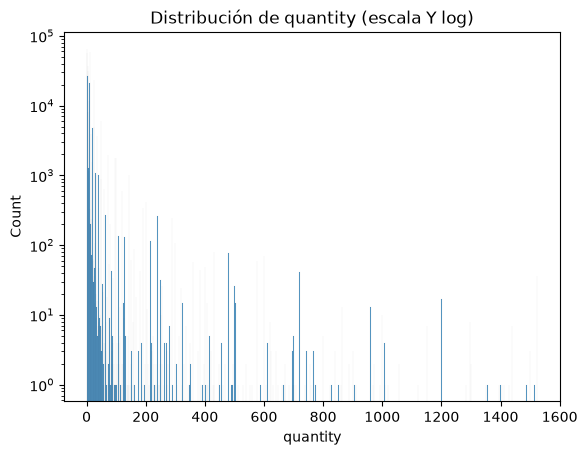

In [37]:
# Log ayudo a la vizualisacion, hay multimodalidad y se puede apreciar los valores tan altos en skewness y kurtosis, la cola se ve terriblemente arrastrada la derecha.

sns.histplot(df_sano_w['quantity'], discrete=True)
plt.yscale('log')
plt.title('Distribución de quantity (escala Y log)')
plt.show()

In [38]:
# Voy a trar de entender los picos que se observan en la distribucion, en la primera visualizacion de prueba que hice note patrones en multiplos de 12, asi es asi, con este codigo sabre donde se ubican realmente la multimodalidad 
# Puedo confirmar el patron, hay compras claras en docenas, medias docenas, los clientes en este negocio se sienten mas comodos comprando en este esquema
# Se documenta para FE; los que compran en docenas o medias docenas pueden ser mayoristas y los que no, comprador final
df_sano_w['quantity'].value_counts().head(15)
df_sano_w[df_sano_w['quantity'] >= 100]['quantity'].value_counts().head(15)

quantity
100.0    1797
144.0    1010
120.0     599
200.0     413
192.0     336
240.0     259
288.0     243
108.0     136
128.0     133
216.0     116
300.0     106
160.0      88
432.0      80
480.0      76
600.0      70
Name: count, dtype: int64

<Axes: ylabel='quantity'>

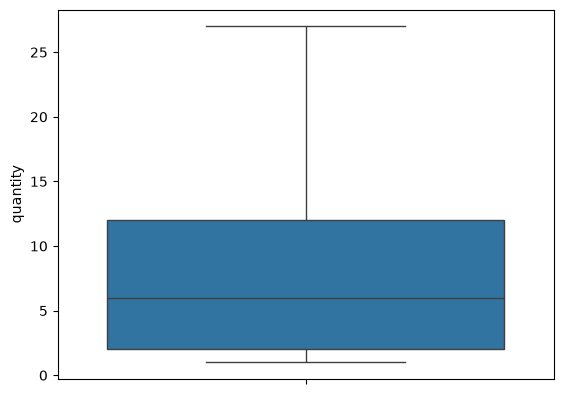

In [39]:
# El negocio tiene sus compras mas importantes entre 2 y 12 unidades, el segmento mas grande de cleintes prefiere hacer sus compras en ese rango.
# Terminando esta primera fase de exploracion basica puedo anotar estos hallazgos rapidos;
# Sesgo brutal en ambas numéricas, multimodalidad por docenas en quantity, mezcla de poblaciones en unitprice.

sns.boxplot(data=df_sano_w['quantity'], showfliers=False)
#sns.boxplot(data=df_sano_w['unitprice'],showfliers=False)

In [40]:
# Pasamos a columnas categoricas
# Hogar domina con casi la mitad del negocio (45%)
# Juguetes es marginal (5.5%) — 8x más pequeño que hogar
# Distribución desbalanceada pero usable: ninguna categoría es <1% (esas sí serían problema)

# Para segmentación esto implica: si un cliente solo compra juguetes, es un perfil raro en el dataset. Eso es informacion valiosa 

df_sano_w['categoria'].value_counts(normalize=True)

categoria
hogar                    0.446498
accesorios_personales    0.193378
cocina                   0.169456
papeleria                0.135687
juguetes                 0.054981
Name: proportion, dtype: float64

In [41]:
# UK = 89% del negocio.
# Las siguientes 3 (Germany, France, EIRE) suman apenas ~6%.
# 20+ países con <1% cada uno. 

# Hay paises con menos del 1% de proporcion dentro del conjunto, ahora mismo la opcion mas viable para mi es hacer binaria la columna, es o no de UK
# Tambian se podrian hacer grupos continentales, grupos de paises que compartan idioma, o grupos geopoliticos que asi tendria mas sentido economico, pero con caulqiera se introduciria sesgo interpretativo
# La menos intrusiva es categoria por grupo continental, se anota para posible fature en FE. 

df_sano_w['country'].value_counts(normalize=True)

country
United Kingdom          0.890750
Germany                 0.022336
France                  0.020721
EIRE                    0.018412
Spain                   0.006244
Netherlands             0.006011
Belgium                 0.005009
Switzerland             0.004686
Portugal                0.003645
Australia               0.003052
Norway                  0.002713
Channel Islands         0.001921
Italy                   0.001918
Finland                 0.001675
Cyprus                  0.001530
Sweden                  0.001103
Austria                 0.000994
Denmark                 0.000950
Poland                  0.000841
Japan                   0.000831
Israel                  0.000626
Unspecified             0.000616
Singapore               0.000557
Iceland                 0.000471
USA                     0.000463
Canada                  0.000386
Greece                  0.000368
Malta                   0.000282
United Arab Emirates    0.000173
European Community      0.000148
RS

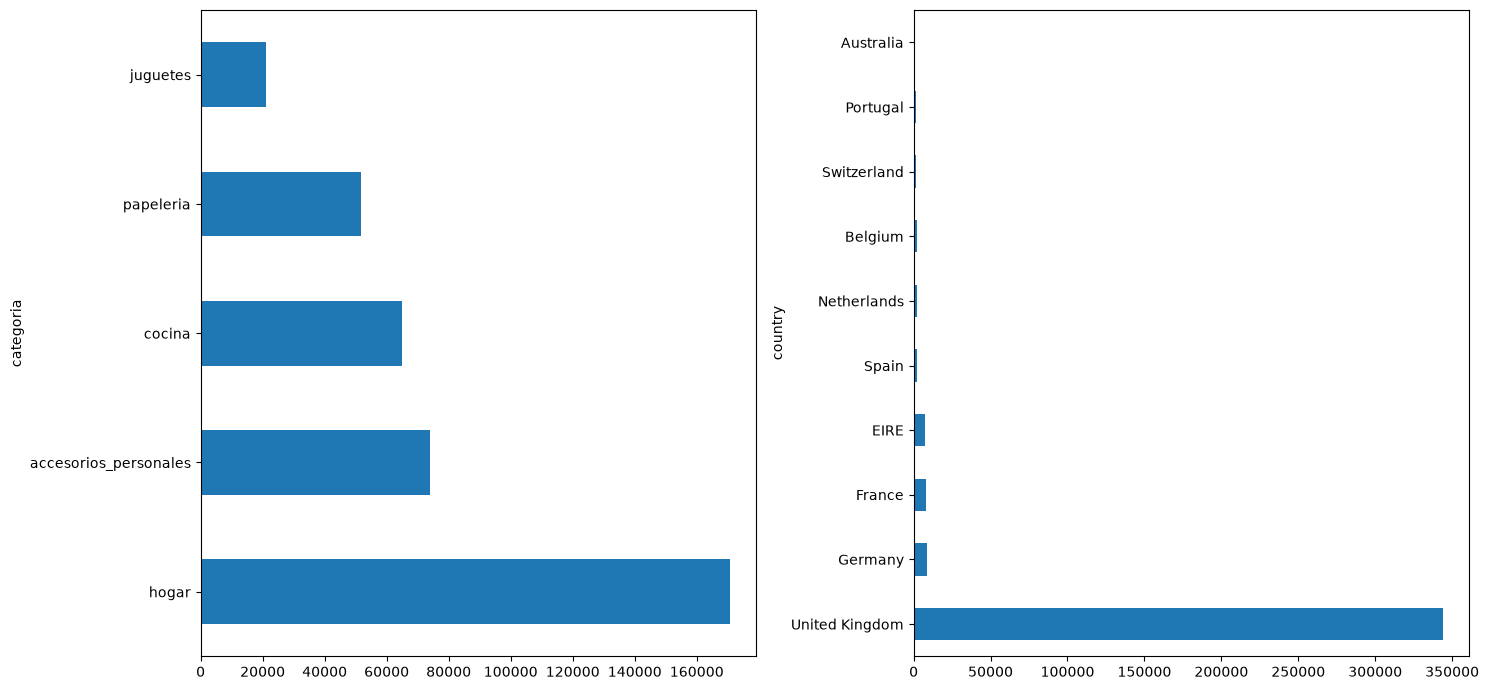

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

df_sano_w['categoria'].value_counts().sort_values(ascending= False).plot(kind='barh', ax=axes[0])
df_sano_w['country'].value_counts().head(10).sort_values(ascending= False).plot(kind='barh', ax=axes[1])

plt.tight_layout()
plt.show()

In [43]:
# Con los descubrimientos hechos generé tres preguntas para guiar la fase de análisis multivariado y bivariado

# Ingresos por tipo de cliente: ¿mayoristas (alto quantity, bajo unitprice) vs minoristas (bajo quantity, alto unitprice) generan más revenue?  requiere derivar revenue = quantity * unitprice y segmentar por ticket/cliente.
# Estacionalidad × categoría: ¿hay concentración de compras por mes, y qué categoría domina cada mes? bivariado invoicedate (mes) × categoria.
# Patrón de ticket: ¿existen "tipos de ticket" recurrentes (mezcla categoría + rango de cantidad + rango de precio)?  multivariado, alimenta directo al K-Means.

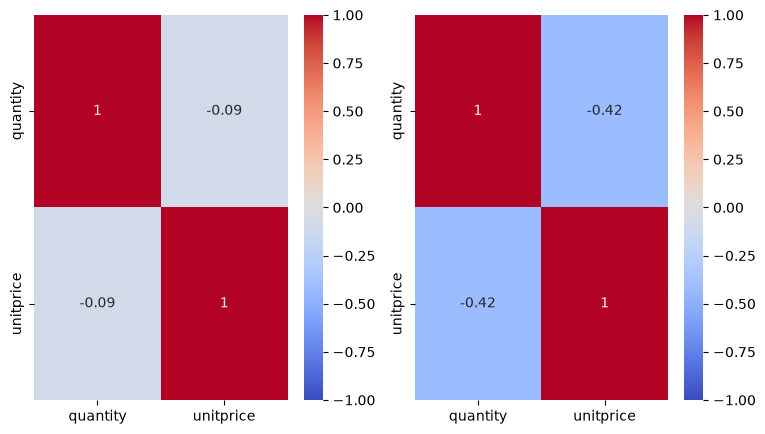

In [44]:
# Numerica x Numerica

# Empezamos con las correlaciones, primero hare correlaciones aplicado en filas individuales, luego, hare en agrupacion por cliente, para tener resultados objetivos tanto para negocio general como para relaciones espeficias de cliente-negocio
# Pearson (−0.09, casi neutro) vs Spearman (−0.42, azul claro) para quantity × unitprice. Confirma que los outliers diluyen Pearson y que Spearman captura la monotonía real.
# Parece haber descuento en funcion de las unidades adquiridas
# No hay multicolinealidad en las variables base, se documenta

df_sano_w_corr = df_sano_w.select_dtypes(include=['number'])
PCorr = df_sano_w_corr.corr(method='pearson')
SCorr = df_sano_w_corr.corr(method='spearman')

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(9, 5))
sns.heatmap(PCorr, ax=axes[0], annot=True, vmin=-1, vmax=1, cmap='coolwarm')
sns.heatmap(SCorr, ax=axes[1], annot=True, vmin=-1, vmax=1, cmap='coolwarm')
plt.show()

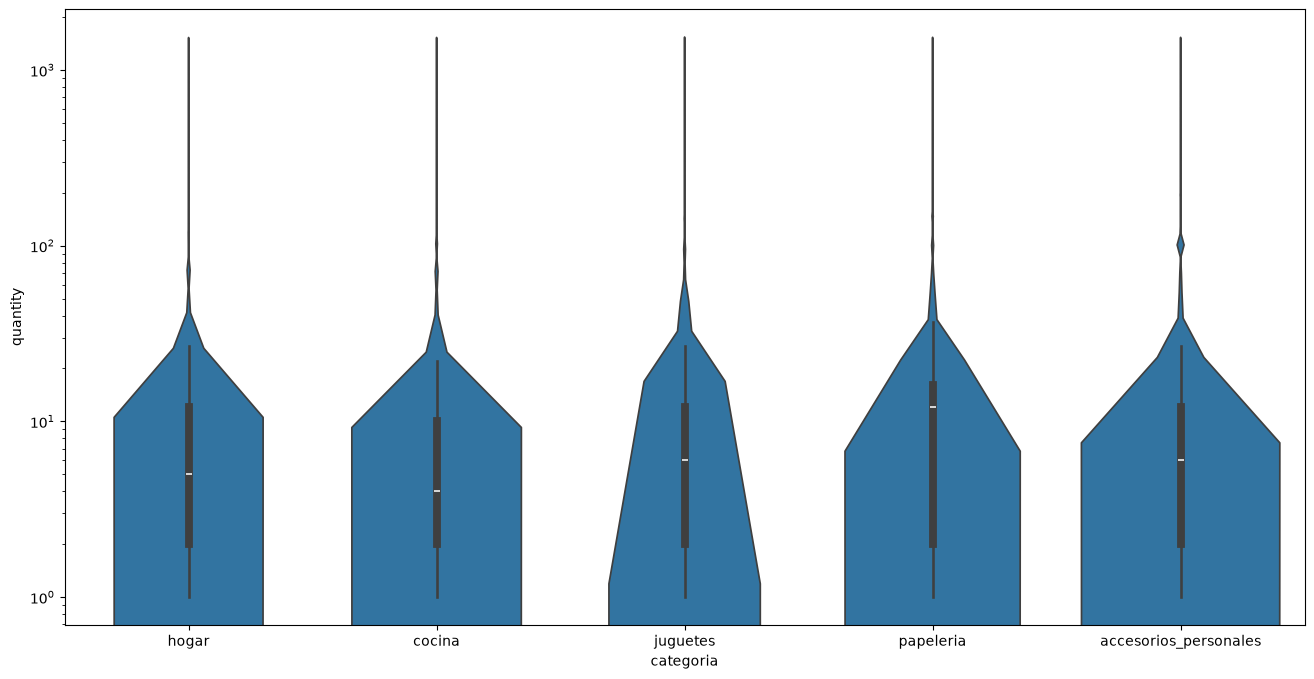

In [45]:
# Guia de exploracion; ¿La cantidad comprada por línea varía según la categoría del producto?
# Numerica x Categorica

# quantity por categoria es similar en las 5 categorías excepto juguetes (distribución aguda, concentrada en valores bajos). 
# Medianas difieren: papelería > cocina. 
# La curtosis 508 no genera colas visibles por categoría — es un fenómeno global, no de una categoría específica.

plt.figure(figsize=(16, 8))
sns.violinplot(x='categoria', y='quantity', data=df_sano_w)
plt.yscale('log')
plt.show()

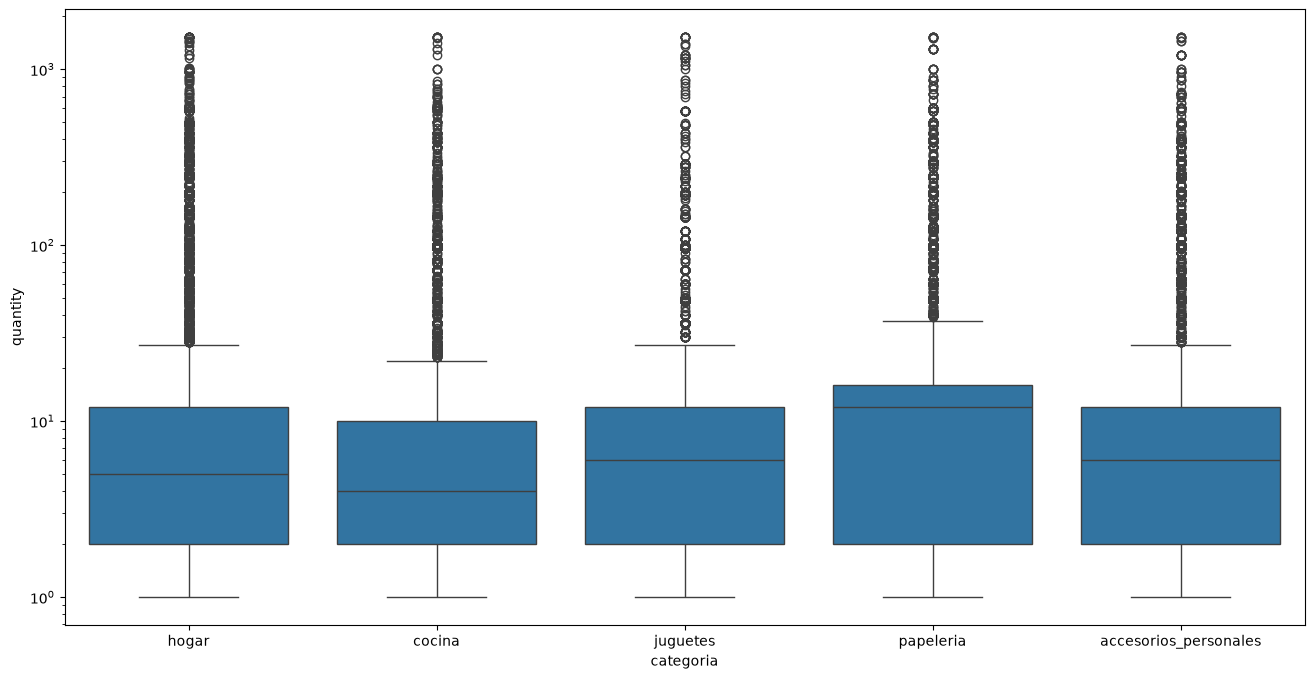

In [46]:
# quntity resulto no ser discriminardor para volumen de compra pues no varia significativamente entre categorias bajo prueba visual de boxplot
# Las diferencias apenas son visibles, aun asi no combiene agrupar por que cada categoria aporta una señal distinta al comportamiento de compra. 
# Con esto en mente dejare fuera categoria para el clustering de volumen por compra, y lo mantendre para ratio por cliente

plt.figure(figsize=(16, 8))
sns.boxplot(x='categoria', y='quantity', data=df_sano_w)
plt.yscale('log')
plt.show()

In [47]:
#  Guia de exploracion; ¿los clientes UK compran un mix de categorías distinto que los no-UK?
# Tomando en cuenta que UK acapara el 89% del negocio, es mas eficiente tomar en cuenta el resto de paises como uno solo.
#  Categorica x Categorica


# V de Cramér country × categoria = 0.049 - asociación muy débil. 
# Categoría comprada es prácticamente independiente del país. Limitación: 89% de datos son UK; países no-UK subrepresentados. 
# No extrapolar conclusiones de negocio global.

import numpy as np
from scipy.stats import chi2_contingency

def v_cramer(col1, col2):
    
    tabla = pd.crosstab(col1, col2)
    chi2, p, dof, expected = chi2_contingency(tabla)
    n = tabla.sum().sum()
    min_dim = min(tabla.shape[0]-1, tabla.shape[1]-1)
    return np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0
    

print(v_cramer(df_sano_w['country'], df_sano_w['categoria']))




0.04881675272705763


In [48]:
# Ingresos por tipo de cliente: ¿mayoristas (alto quantity, bajo unitprice) vs minoristas (bajo quantity, alto unitprice) generan más revenue?  requiere derivar revenue = quantity * unitprice y segmentar por ticket/cliente.
# Estacionalidad × categoría: ¿hay concentración de compras por mes, y qué categoría domina cada mes? bivariado invoicedate (mes) × categoria.
# Patrón de ticket: ¿existen "tipos de ticket" recurrentes (mezcla categoría + rango de cantidad + rango de precio)?  multivariado, alimenta directo al K-Means.
# Paso 13 pospuesto hasta tener revenue, mes, ticket_prom, recency, etc. Ahí sí hay pares que vale la pena scatterear.



# K-Means se hará sobre features de comportamiento + log-transform donde aplique.


# post-K-Means: si los clusters salen desbalanceados, revisar si colapsar categorías o reformular features

In [49]:
# Ahora voy a tratar los outliers legitimos en el conjunto de datos 

# Dado que voy a trabajar con K-Means, quiero que la media represente adecuadamente la distribucion en unitprice
# A partir de 200 en unitprice el numero de filas baja bastante y es el numero que me preocupa a parte de un par de filas que tienen como valor 600
# Si Wisorizo todas las filas arriba de 200 apenas perderia 8 clientes de 4333, el 0.18% del total, pero el riesgo de ello es perder señal valiosa del sector de clientes que compran arituclos mas caros de lo normal


clientes_caros = df_sano_w[df_sano_w['unitprice'] > 200]['customerid'].nunique()
print("Clientes con al menos una línea >£200:", clientes_caros)
print("Total clientes únicos:", df_sano_w['customerid'].nunique())


# Corte en 295, valor informado por el hueco natural en la distribución (no hay valores entre £296 y £600) ubicado en el percentil 99.999.
print("P99.999 unitprice:", df_sano_w['unitprice'].quantile(0.99999))
print("Max actual:", df_sano_w['unitprice'].max())


# Antes de Winsorizar eliminare uno de los dos datos peligrosos, ambos tienen unitprice de 600, uno con 60 unidades y otro con uno, no puedo comprobar que ninguno es falso puesto que no parece haber error de captura
# Asi que eliminare el mas incoherente en funcion de lo que suele comprarse en el negocio como mayoreo, el de 60 unidades
df_sano_w= df_sano_w.drop(index= 222680)

# Ahora Winsorizo con el dato eliminado.
maximo_natural = df_sano_w['unitprice'].quantile(0.99999)
df_sano_w['unitprice'] = df_sano_w['unitprice'].clip(upper= maximo_natural)




Clientes con al menos una línea >£200: 8
Total clientes únicos: 4333
P99.999 unitprice: 295.0
Max actual: 649.5


In [50]:
# Cotinuo con el tratamiento de las variables con Skewness severo
# Voy a aplicar log1p a las columnas numericas para ver cuanto disminuye Skewness 



df_sano_w_skew = df_sano_w[['quantity','unitprice']].skew()

df_sano_w['unitprice_log'] = np.log1p(df_sano_w['unitprice'])
df_sano_w['quantity_log']= np.log1p(df_sano_w['quantity'])




df_sano_w_skew_log = df_sano_w[['quantity_log','unitprice_log']].skew()

df_sano_w_skew_log = df_sano_w_skew_log.rename(index={
    'quantity_log': 'quantity',
    'unitprice_log': 'unitprice'
})

comparacion_skew = pd.concat(
    [df_sano_w_skew.rename('Antes'), df_sano_w_skew_log.rename('Despues')],
    axis=1
)
print(comparacion_skew)

# Ambas quedaron por debajo de 1, de momento continuare con ese resultado  
# Aplique un segundo log1p, pero veo que la diferencia es minima y tampoco quiero perder señal valiosa por ganar unas cuentas milesimas, se queda con una sola transformacion. 

               Antes   Despues
quantity   18.071655  0.804701
unitprice  22.327822  0.764532


In [51]:
# log1p resulto tener valor interpretable, probare con Box-cox, para ver cual me combiene incluir en el modelo.
# Yeo Jhonson no me funciona por que no tengo valores negativos ni muchos ceros, Box-cox es ideal para este conjunto por el momento


# Box-cox salio con mejor separacion entre segmentos pero log1p tiene mejor interpretabilidad
# Usare Box-cox para el modelo y guardare log1p como capa interpretable para comunicacion de EDA a skateholders

from scipy.stats import boxcox

q_bc, lambda_q = boxcox(df_sano_w['quantity'])
u_bc, lambda_u = boxcox(df_sano_w['unitprice'])

from scipy.stats import skew

print("quantity:", lambda_q, " skew despues:", skew(q_bc))
print("unitprice:", lambda_u, " skew despues:", skew(u_bc))

quantity: -0.1427338797626264  skew despues: 0.03775440459234661
unitprice: 0.012813056478520353  skew despues: 8.376511244448556e-05


In [52]:
# Ahora dividire el df en dos conjuntos para empezar con FE, uno con los clientes con id y otro solamente con los clientes desconocidos
# La idea es estudiar ambos grupos por separado, los deconocidos serviran como referencia para skateholders para comunicar su valor practico y cuanto cuesta no saber la id del cliente


df_clientes = df_sano_w[df_sano_w['customerid'] != 'DESCONOCIDO'].copy()
df_desconocido = df_sano_w[df_sano_w['customerid'] == 'DESCONOCIDO'].copy()

In [53]:
# Empezamos con RFM clasico 

# revenue
df_clientes['revenue'] = df_clientes['quantity'] * df_clientes['unitprice']

# Referencia de fecha maxima dentro del conjunto
fecha_max = df_clientes['invoicedate'].max()

# Agregacion RFM
df_rfm = df_clientes.groupby('customerid').agg(
    monetary = ('revenue','sum'),
    frequency = ('invoiceno','nunique'),
    recency = ('invoicedate','max')
)

# Ahora modifico correctamente recency a dias para que el modelo trabaje correctamente con la cifra
df_rfm['recency'] = (fecha_max - df_rfm['recency']).dt.days


# Hare una verificacion rapida con el top 3 clientes mas altos 
print(df_rfm.shape)
print(df_rfm.describe())
print(df_rfm.sort_values('monetary', ascending=False).head(3))

# monetary y frencuency tal vez necesiten una transformacion igual que quantity y uniteprice, tambien se nota el Skewness 


(4333, 3)
            monetary    frequency      recency
count    4333.000000  4333.000000  4333.000000
mean     1939.144648     4.246019    91.696515
std      8397.376285     7.635748   100.130990
min         2.900000     1.000000     0.000000
25%       302.200000     1.000000    17.000000
50%       657.300000     2.000000    50.000000
75%      1614.910000     5.000000   142.000000
max    277169.676000   206.000000   373.000000
               monetary  frequency  recency
customerid                                 
14646       277169.6760         72        1
18102       259657.3000         60        0
17450       192941.9828         46        7


In [54]:
# Revisare los clientes top 3 para verificar que sean legitimos


top3 = df_clientes[df_clientes['customerid'].isin(['14646', '18102', '17450'])]
print(top3.groupby('customerid').agg(
    quantity_media=('quantity', 'mean'),
    unitprice_medio=('unitprice', 'mean'),
    lineas=('invoiceno', 'count'),
    categorias=('categoria', lambda x: x.value_counts().head(2).to_dict())
))

# Parecen ser mayoristas legitimos, alto quantity y bajo unitprice, de haber winsorizado al 99.99 habria perdido informacion de los clientes mas rentables del conjunto 


            quantity_media  unitprice_medio  lineas  \
customerid                                            
14646            95.031282         2.394704    2060   
17450           205.252716         3.365134     335   
18102           148.779582         4.503295     431   

                                              categorias  
customerid                                                
14646       {'accesorios_personales': 663, 'hogar': 582}  
17450                       {'hogar': 255, 'cocina': 63}  
18102                       {'hogar': 353, 'cocina': 59}  


In [55]:
# Hare una revision de los percentiles en quantity y tratar de fijar el umbral para una variable de ratio sobre clientes mayoristas.

qty_por_factura = df_clientes.groupby('invoiceno')['quantity'].sum()
print("Mediana:", qty_por_factura.median())
print("P75:", qty_por_factura.quantile(0.75))
print("P90:", qty_por_factura.quantile(0.90))
print("P95:", qty_por_factura.quantile(0.95))

Mediana: 154.0
P75: 290.0
P90: 511.0
P95: 774.0


In [56]:
# No poseo informacion externa que sugiera algun umbral estandar de reventa sobre las facturas.
# Asi que usare el percentil 75 ya que siempre capturaria por encima de el, el 25% de facturas con mas volumen.
# Es arbitrario pero para esta situacion con falta de informacion es ideal. 

# La idea de la variable es determinar el porcentaje de facturas mayoristas que tiene cada cliente y cubrir un eje extra que no esta en el RFM estandar. 
umbral = 290
qty_factura = df_clientes.groupby(['customerid','invoiceno'])['quantity'].sum().reset_index()
qty_factura['es_mayorista'] = (qty_factura['quantity'] > umbral).astype(int)
pct_mayorista = qty_factura.groupby('customerid')['es_mayorista'].mean()

df_rfm['pct_mayorista'] = pct_mayorista




In [57]:
# Ahora tratare de cubrir otros dos ejes extras para el modelo
# Uno con el quantity total de cada cliente 
# Otro con el auntity total de cada factura 

df_rfm['quantity_total'] = df_clientes.groupby('customerid')['quantity'].sum()
df_rfm['units_per_invoice'] = df_rfm['quantity_total']/df_rfm['frequency']

print(df_rfm[['quantity_total','units_per_invoice']].describe())



       quantity_total  units_per_invoice
count     4333.000000        4333.000000
mean      1140.238615         225.518061
std       4729.959208         287.153768
min          1.000000           1.000000
25%        158.000000          91.840000
50%        372.000000         160.000000
75%        986.000000         270.000000
max     195764.440000        7824.000000


In [58]:
# Ahora hare una variable binaria para clientes de temporada
# Ya tenia la sospecha de presencia significativa de compras navideñas en el conjunto, hare un filtro rapido para saber si la variable podria ser significativa 
# Usare description para configurar el filtro, no invoicedate, por falta de parametros discriminatorios en la variable, puede que pierda compras navideñas pero usando description con 'CHRISTMAS' sera mas preciso. 

# El filtro arrojo 18568 filas
capa_navideña = df_clientes[df_clientes['description'].str.contains('CHRISTMAS',na=False)]

# Estoy indecisio si usar un filtro por facturas o por lineas con compras navideñas
# La idea era discriminar clientes abajo de 3 facturas, con esta verificacion me di cuenta de que es mala idea, estaria ignorando mas o menos un %50 de clientes
print((df_rfm['frequency'] < 3).sum(), "clientes con <3 facturas")
print((df_rfm['frequency'] < 5).sum(), "clientes con <5 facturas")


# Hare del filtro por lineas de compras dentro de cada factura y promediare por cliente igual que el ratio de mayoristas por cliente

df_clientes['es_navideño'] = df_clientes['description'].str.contains('CHRISTMAS', case=False, na=False).astype(int)

nav_factura = df_clientes.groupby(['customerid','invoiceno'])['es_navideño'].mean().reset_index()
nav_factura['factura_navideña'] = (nav_factura['es_navideño']>= 0.50).astype(int)


pct_navideño = nav_factura.groupby('customerid')['factura_navideña'].mean()
#df_rfm['pct_navideño'] = pct_navideño

#print(df_rfm['pct_navideño'].describe())
#print((df_rfm['pct_navideño'] > 0).sum(), "clientes con al menos 1 factura navideña")

# La señal es muy debil, el 75% no tiene nada navideño, la descartare. 


2336 clientes con <3 facturas
3232 clientes con <5 facturas


In [59]:
# Hare una variable de timpo de vida por cliente para capturar un eje extra aparte de frequency.

v_rango_vida = df_clientes.groupby('customerid')['invoicedate'].agg(['min','max'])
df_rfm['rango_vida'] = (v_rango_vida['max'] - v_rango_vida['min']).dt.days

# Aproximadamente un tercio de los clientes ha comprado una sola vez, es informacion valiosa para el negocio. 
print(df_rfm['rango_vida'].describe())
print("% con rango 0:", (df_rfm['rango_vida'] == 0).mean() * 100)

count    4333.000000
mean      130.269328
std       132.100090
min         0.000000
25%         0.000000
50%        92.000000
75%       252.000000
max       373.000000
Name: rango_vida, dtype: float64
% con rango 0: 36.09508423724902


In [60]:
# Por ultimo aprovechare las 5 categorias clasificadas de description para hacer una variable
# EDA descrubio que hogar tiene preferencia dentro del negocio, dominando un 45% del total, tiene mas sentido para mi aprovechar ese dominio y hacer una sola variable de ratio sobre hogar 
# que hacer 4 variables - 1 (para evitar colinealidad) cuando la señal mas fuerte casi siempre sera de hogar 

# Primero hare una verificacion para determinar si la variable sera buen discriminante
pct_hogar = df_clientes.groupby('customerid').apply(lambda x: (x['categoria']== 'hogar').mean())
print(pct_hogar.describe())
print("Clientes con >50% hogar:", (pct_hogar > 0.5).mean() * 100, "%")

# Los porcentajes son prometedores y hay buena variedad dentro de las preferencias


# Ahora hare una funcion para que reste los nulos de los productos no clasificados para ver cuantos clientes con filas completas no estan clasificadas y ver si la distribucion se sesga mucho
def pct_hogar(x):
    valido = x['categoria'].notna()
    if valido.sum() == 0:
        return np.nan
    return (x.loc[valido,'categoria'] == 'hogar').mean()

df_rfm['pct_hogar'] = df_clientes.groupby('customerid').apply(pct_hogar)

print(df_rfm['pct_hogar'].describe())
print("Nulos en pct_hogar:", df_rfm['pct_hogar'].isna().sum())

# Solo 4 clientes tienen filas completas sin clasificar en description, no los voy a eliminar por que siguen aportando señal importante a las demas variables
# Voy a imputar con la mediana, considero que es el metodo menos invasivo y solo moveria aproximadamente un 0.8% del conjunto. 

count    4333.000000
mean        0.464181
std         0.226707
min         0.000000
25%         0.312500
50%         0.447368
75%         0.600000
max         1.000000
dtype: float64
Clientes con >50% hogar: 38.56450496192015 %
count    4329.000000
mean        0.470921
std         0.229333
min         0.000000
25%         0.317073
50%         0.454545
75%         0.609756
max         1.000000
Name: pct_hogar, dtype: float64
Nulos en pct_hogar: 4


In [61]:
# Ahora evaluare el Skewness de las features creadas 


skew_rfm = df_rfm.skew().sort_values(ascending = False)
print(skew_rfm)

quantity_total       22.408065
monetary             21.103544
frequency            11.948571
units_per_invoice     8.888027
pct_mayorista         1.349421
recency               1.242724
rango_vida            0.456831
pct_hogar             0.300703
dtype: float64


In [62]:
# Sigue multicolinealidad
# Ninguna arriba de 9, es buena señal aunque para K-means no resulte restrictivo.

from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df_rfm.fillna(df_rfm.median())
vif = pd.DataFrame({
    'feature': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
}).sort_values('VIF', ascending=False)
print(vif)

             feature       VIF
4     quantity_total  7.578292
0           monetary  6.893883
1          frequency  1.979544
5  units_per_invoice  1.957516
3      pct_mayorista  1.661279
6         rango_vida  1.649398
2            recency  1.374069
7          pct_hogar  1.037632


In [63]:
# Revisare vairianza 0 y Nan finales para empezar con las imputaciones y transformaciones nescesarias. 
# Todas aportan, ninguna con varianza en 0 

# Hago imputacion de pct_hogar por que hay 4 clientes Nan debido a que tienen solo facturas con articulos sin categoria asignada, debe ser por los productos que deje sin clasificar en limpieza
# Imputar con la media es la via menos intrusiva y al ser menos del 1% es aceptable para este caso. 

df_rfm['pct_hogar'] = df_rfm['pct_hogar'].fillna(df_rfm['pct_hogar'].mean())

print(df_rfm.isna().sum())
print(df_rfm.std().sort_values())



monetary             0
frequency            0
recency              0
pct_mayorista        0
quantity_total       0
units_per_invoice    0
rango_vida           0
pct_hogar            0
dtype: int64
pct_hogar               0.229227
pct_mayorista           0.339394
frequency               7.635748
recency               100.130990
rango_vida            132.100090
units_per_invoice     287.153768
quantity_total       4729.959208
monetary             8397.376285
dtype: float64


In [64]:
# Hare transformacion segun el skew de las variables y estandarizare con StandardScaler 

from scipy.stats import boxcox, yeojohnson

a_transformar = ['quantity_total', 'monetary', 'frequency',
                 'units_per_invoice', 'pct_mayorista', 'recency']
simetricas   = ['pct_hogar', 'rango_vida']

df_transformado = df_rfm[simetricas].copy()

for col in a_transformar:
    x = df_rfm[col].values
    if x.min() > 0:
        df_transformado[col] = boxcox(x)[0]
    else:
        df_transformado[col] = yeojohnson(x)[0]

print(df_transformado.skew().sort_values(ascending=False))



from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_transformado)


X_scaled_df = pd.DataFrame(X_scaled, columns=df_transformado.columns)
print(X_scaled_df.describe().loc[['mean','std']].T)
print(X_scaled_df.skew().sort_values(ascending=False))


pct_mayorista        0.684021
rango_vida           0.456831
pct_hogar            0.300842
frequency            0.147356
units_per_invoice    0.058817
quantity_total       0.000644
monetary            -0.016608
recency             -0.070414
dtype: float64
                           mean       std
pct_hogar          1.213482e-16  1.000115
rango_vida        -1.803824e-17  1.000115
quantity_total    -1.574247e-16  1.000115
monetary           3.870023e-16  1.000115
frequency         -4.345576e-17  1.000115
units_per_invoice -3.673242e-16  1.000115
pct_mayorista     -1.967808e-17  1.000115
recency           -9.183105e-17  1.000115
pct_mayorista        0.684021
rango_vida           0.456831
pct_hogar            0.300842
frequency            0.147356
units_per_invoice    0.058817
quantity_total       0.000644
monetary            -0.016608
recency             -0.070414
dtype: float64


In [65]:
# Con los datos preparados corri K-means
# Esperaba 5 segmentos bien distribuidos 
# Pero esta entre 4 y 5, la caida no es brusca, cae suavmente en el numero 5

# En funcion de una posible campaña de activacion en alguno de los clusters, mientras menos clusters sean mejor, el costo de activacion por cluster sera menor y mas rentable para el negocio


from sklearn.cluster import KMeans

inercias = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inercias.append((k, km.inertia_))

for k, i in inercias:
    print(f"K={k:2d}  inertia={i:,.0f}")

K= 2  inertia=21,955
K= 3  inertia=17,943
K= 4  inertia=14,949
K= 5  inertia=13,389
K= 6  inertia=12,480
K= 7  inertia=11,626
K= 8  inertia=10,903
K= 9  inertia=10,345
K=10  inertia=9,844


In [66]:
# Ahora toca ver la distancia de datos-centroide con Davies-Bouldin, por la desviacion estandar considero que caera en 4 el minimo.

from sklearn.metrics import davies_bouldin_score

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    db = davies_bouldin_score(X_scaled, labels)
    print(f"K={k:2d}  DB={db:.4f}")

# 1.2241 en 4, la desviacion estandar si afecto como esperaba. 
# Con 4 segmentos podemos asegurar que los clusters saldran solidos.

K= 2  DB=1.2329
K= 3  DB=1.2405
K= 4  DB=1.2241
K= 5  DB=1.3533
K= 6  DB=1.4038
K= 7  DB=1.4240
K= 8  DB=1.3793
K= 9  DB=1.4529
K=10  DB=1.3889


In [67]:
# Ahora correre pruebas para verificar la estabilidad de los segmentos con Adjusted Rand Index

from sklearn.metrics import adjusted_rand_score
import itertools

semillas = [0, 1, 42, 100, 777]
asignaciones = {}

for s in semillas:
    km = KMeans(n_clusters=4, n_init=10, random_state=s)
    asignaciones[s] = km.fit_predict(X_scaled)

print("ARI entre pares de semillas:")
for a, b in itertools.combinations(semillas, 2):
    ari = adjusted_rand_score(asignaciones[a], asignaciones[b])
    print(f"  {a:>3} vs {b:>3}: {ari:.3f}")

# Excelente acuerdo entre todos los pares, hice algunas pruebas entre 4-6 clusters y la diferencia es minima.
# La estructura con estos 8 features es robusta y la diferencia entre 4 y 5 apenas varia por 0.03 en ARI 

ARI entre pares de semillas:
    0 vs   1: 1.000
    0 vs  42: 0.999
    0 vs 100: 1.000
    0 vs 777: 1.000
    1 vs  42: 0.999
    1 vs 100: 1.000
    1 vs 777: 1.000
   42 vs 100: 0.999
   42 vs 777: 0.999
  100 vs 777: 1.000


In [68]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
idx = df_rfm.index
labels = kmeans.fit_predict(X_scaled)
df_rfm['cluster'] = pd.Series(labels, index=idx)

In [69]:
# Revisando los segmentos que arrojo K-means, hay dos segmentos con cantidades que no me cuadran en pct_mayorista y units_per_invoice


perfil = df_rfm.groupby('cluster')[
    ['recency', 'frequency', 'monetary',
     'quantity_total', 'units_per_invoice',
     'pct_mayorista', 'rango_vida', 'pct_hogar']
].mean().round(2)

perfil['n_clientes'] = df_rfm.groupby('cluster').size()
perfil

,recency,frequency,monetary,quantity_total,units_per_invoice,pct_mayorista,rango_vida,pct_hogar,n_clientes
cluster,,,,,,,,,
0,24.67,10.53,6285.22,3750.49,337.70,0.41,275.98,0.43,970
1,160.58,1.27,265.67,134.64,114.50,0.00,14.54,0.50,1543
2,46.84,4.42,981.77,471.26,116.95,0.01,207.76,0.50,1118
3,104.35,1.84,1136.88,809.20,487.44,0.77,59.90,0.41,702


In [70]:
# Voy verificar si hay algun segmento que esconda subpoblaciones en sus distribuciones y hayan dos perfiles mezclados en uno solo


for c in [0, 1, 2, 3]:
    sub = df_rfm[df_rfm['cluster'] == c]
    print(f"\nCluster {c} (n={len(sub)})")
    print(sub[['monetary', 'pct_mayorista']].describe().loc[['mean','std','min','25%','50%','75%','max']].round(2))

# Confirmo que hay un cluster con dos perfiles mezclados
# El cluster 0 tiene de media 6285 en monetary y con una desviacion estandar de 16929
# min=517, max=277,169. El cliente más grande del cluster gasta 540x el más chico
# La media no representa a nadie: la mitad de los clientes gasta <= 3,039, pero la media es 6,285 (inflada por outliers)

# El segmento es heterogeneo con perfiles de 500 en monetary hasta 277k 
# Ademas, el coeficiente de variacion es 2.7 



Cluster 0 (n=970)
       monetary  pct_mayorista
mean    6285.22           0.41
std    16969.50           0.27
min      517.80           0.00
25%     1969.35           0.20
50%     3039.50           0.36
75%     5136.06           0.60
max   277169.68           1.00

Cluster 1 (n=1543)
      monetary  pct_mayorista
mean    265.67            0.0
std     165.94            0.0
min       2.90            0.0
25%     144.43            0.0
50%     228.20            0.0
75%     347.54            0.0
max    1289.50            0.0

Cluster 2 (n=1118)
      monetary  pct_mayorista
mean    981.77           0.01
std     704.71           0.04
min      52.20           0.00
25%     538.10           0.00
50%     787.50           0.00
75%    1200.99           0.00
max    7374.90           0.33

Cluster 3 (n=702)
      monetary  pct_mayorista
mean   1136.88           0.77
std    1567.07           0.27
min      90.48           0.20
25%     558.71           0.50
50%     863.00           1.00
75%    1317.23

In [71]:
# Mi descision sera nombrar con la mediana y abordar ese 20% del cluster despues con analisis enfocado, no reabrire K-means por que 4 segmentos sigue siendo tecnicamente solido

# Esto le diria a Skateholders para justificar la descicion:
# Cluster 0 = 'Clientes de valor consolidado', con perfil de gasto mixto. La media engaña: la mitad gasta <= 3k, la cola alta llega a 277k. Recomiendo tratarlo como segmento con cola, no como bloque homogéneo.


# README

# pct_mayorista — Proporción del volumen de unidades compradas (quantity) facturado a precio mayorista para cada cliente. Rango: [0.0, 1.0]. Interpretación: 0.77 indica que 77% de las unidades que compró ese cliente fueron a tarifa mayorista; 0.0 indica cliente puramente minorista.
# rango_vida — Número de días entre la primera y la última compra del cliente (rango de vida transaccional). Rango: [0, N] días, donde 0 = cliente con una sola factura (sin vida observable). Interpretación: 278 = cliente activo durante 278 días; 0 = comprador único, no recurrente (aplica al 36% del dataset)
# units_per_invoice — Promedio de unidades compradas por factura para cada cliente, calculado como quantity_total / frequency. Rango: [1, N] unidades/factura (mínimo 1 si toda compra tiene al menos 1 unidad). Interpretación: 377 = en promedio, cada factura del cliente contiene 377 unidades. Valores altos identifican compras concentradas en pocas facturas grandes (mayoristas); valores bajos, compras distribuidas (minoristas).
# pct_hogar — Proporción del volumen de compra del cliente correspondiente a la categoría hogar. Rango: [0.0, 1.0]. Interpretación: 0.50 = la mitad de las unidades que compró ese cliente son de categoría hogar; valores altos indican alta dependencia de esa categoría (posible cliente residencial o pequeño negocio de ese rubro).
# quantity_total — Suma de unidades (quantity) de todas las facturas del cliente. Rango: [1.00, 195,764.44] tras limpieza (unidades negativas excluidas como devoluciones). Interpretación: 3750 = el cliente acumuló 3750 unidades compradas en su historial.
# monetary — Suma del valor monetario (quantity × unitprice) de todas las facturas del cliente. Rango: [2.90, 277,169.68] en £ (tras winsorización de unitprice a £295). Interpretación: 6285 = el cliente ha generado £6,285 en ingresos totales para el negocio.
# frequency — Número de facturas únicas (nunique de InvoiceNo) por cliente. Rango: [1, N] facturas (todo cliente del dataset tiene al menos una). Interpretación: 7 = el cliente ha facturado 7 veces distintas en su historial.
# recency — Días transcurridos entre la última compra del cliente y la fecha de referencia del dataset (último día registrado). Rango: [0, 373] días; 0 = compró el último día. Interpretación: 24 = el cliente compró por última vez hace 24 días; valores bajos = activo reciente, valores altos = riesgo de fuga.

# Hallazgo central: el 22% de los clientes (cluster 0, 970 clientes) concentra el 72.6% de los ingresos (£6,096,662 de £8,402,313 totales). En contraste, el 35% de la base (cluster 1, 1,543 clientes) aporta solo 4.9% — son compradores únicos de bajo ticket, objetivo de campaña de recompra. Acción: retención + up-selling en cluster 0 y 3; activación de segunda compra en cluster 1. Segmentación realizada con K-Means (K=4, validado por Davies-Bouldin y estabilidad ARI > 0.999).

In [72]:
# Ahora calculare el porcentaje de ingreso de cada cluster 
# Tomando en cuenta que el cluster 0 conforma el 22% de los clientes, genera el 72.5% de los ingresos. 
# Eso es una desproporción 3.2x — no es pareto perfecto (80/20), es más concentrado aún. 
# Y el cluster 1 (35% de la base) genera solo 4.88% ese es el segmento de activación/recompra, no de retención premium. 

ingreso_por_cluster = df_rfm.groupby('cluster')['monetary'].sum()
pct_ingreso = (ingreso_por_cluster / df_rfm['monetary'].sum() * 100).round(2)
print(pct_ingreso)

cluster
0    72.56
1     4.88
2    13.06
3     9.50
Name: monetary, dtype: float64


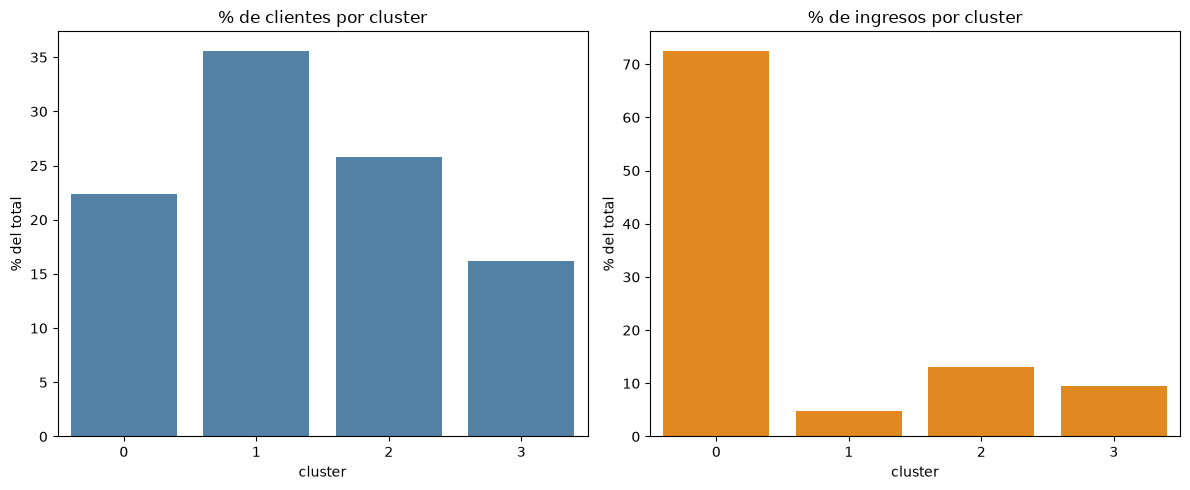

In [73]:
# Grafica de comparacion de poblaciones e ingresos por cluster 

agg = df_rfm.groupby('cluster').agg(
    n_clientes=('cluster', 'size'),
    ingresos=('monetary', 'sum')
)


agg['pct_clientes'] = agg['n_clientes'] / agg['n_clientes'].sum() * 100
agg['pct_ingresos'] = agg['ingresos'] / agg['ingresos'].sum() * 100


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x=agg.index, y=agg['pct_clientes'], ax=axes[0], color='steelblue')
axes[0].set_title('% de clientes por cluster')
axes[0].set_ylabel('% del total')

sns.barplot(x=agg.index, y=agg['pct_ingresos'], ax=axes[1], color='darkorange')
axes[1].set_title('% de ingresos por cluster')
axes[1].set_ylabel('% del total')

plt.tight_layout()
plt.show()

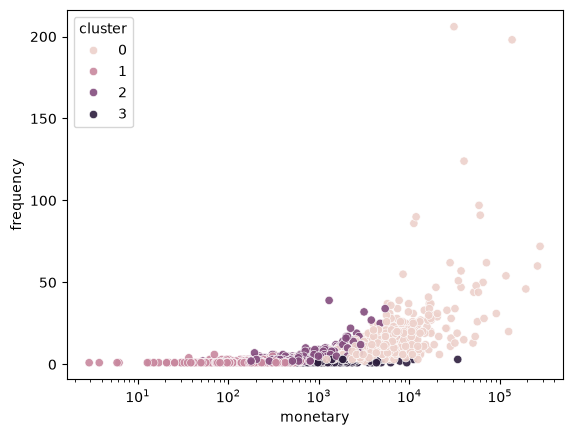

In [74]:

sns.scatterplot(data=df_rfm, x='monetary', y='frequency', hue='cluster', alpha=0.9)
plt.xscale('log')  

In [75]:
# Empezamos con Market Basket y reglas de ascosiacion del top 20% del cluster 0 que es el sector con clientes mas rentables de todo el negocio. 

# Primero unire los nuevos clusters con el df_clientes para tener todas las columnas necesarias para empezar las reglas de asociacion


df_clientes_cluster = pd.merge(
    df_clientes,
    df_rfm[['cluster', 'monetary']],
    left_on='customerid',
    right_index=True,
    how='inner'
)

# Separare el cluster 0 del resto del conjunto y luego separare el top 20 del resto del cluster

clientes_c0 = df_rfm[df_rfm['cluster']== 0].copy()
umbral = clientes_c0['monetary'].quantile(0.80)
top20_ids = clientes_c0[clientes_c0['monetary'] >= umbral].index

# Ahora agrupare en la misma fila descripciones no repetidas para que las reglas de asociacion no tengan productos repetidos con precios o tamaños diferentes

df_top20 = df_clientes_cluster[df_clientes_cluster['customerid'].isin(top20_ids)]
canastas = df_top20.groupby('invoiceno')['description'].apply(lambda x: list(set(x)))




In [76]:
print(f"Clientes en top 20% cluster 0: {len(top20_ids)}")
print(f"Facturas (canastas) en top 20%: {len(canastas)}")
print(f"Ítems únicos: {len(set().union(*canastas))}")
print(f"Tamaño promedio canasta: {canastas.apply(len).mean():.2f}")

# 3,386 ítems únicos en 4,681 canastas. 
# Eso es una dispersión brutal — en promedio, cada ítem aparece en 1.4 canastas.
# La mayoría de productos aparecen una sola vez y puede no haber patrón posible.
# Usare min_support = 0.02, para un minimo de 94 canastas, seguramente no obtenga muchas reglas pero las pocas que pueda encontrar seran valiosas. 

Clientes en top 20% cluster 0: 194
Facturas (canastas) en top 20%: 4681
Ítems únicos: 3386
Tamaño promedio canasta: 20.79


In [77]:
# Primero hago la matriz para que apriori pueda trabajar 
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
matriz = te.fit(canastas).transform(canastas)
df_canastas = pd.DataFrame(matriz, columns= te.columns_)

In [78]:
# Aplico apriori y antes de ordenar en pares primero quiero observar cuales son los porductos individuales que aparecen mas
from mlxtend.frequent_patterns import apriori, association_rules

itemsets = apriori(df_canastas, min_support=0.02, use_colnames=True)
print(f"Itemsets frecuentes: {len(itemsets)}")
print(itemsets.sort_values('support', ascending=False).head(15))

Itemsets frecuentes: 276
      support                                         itemsets
159  0.114505            frozenset({REGENCY CAKESTAND 3 TIER})
86   0.110019             frozenset({JUMBO BAG RED RETROSPOT})
210  0.090365  frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
106  0.088015             frozenset({LUNCH BAG RED RETROSPOT})
129  0.076479                       frozenset({PARTY BUNTING})
178  0.066012   frozenset({SET OF 3 CAKE TINS PANTRY DESIGN })
168  0.063021    frozenset({ROSES REGENCY TEACUP AND SAUCER })
121  0.061953     frozenset({PACK OF 72 RETROSPOT CAKE CASES})
10   0.061739           frozenset({ALARM CLOCK BAKELIKE RED })
84   0.061525             frozenset({JUMBO BAG PINK POLKADOT})
99   0.059816             frozenset({LUNCH BAG  BLACK SKULL.})
181  0.059175        frozenset({SET OF 4 PANTRY JELLY MOULDS})
13   0.058535       frozenset({ASSORTED COLOUR BIRD ORNAMENT})
6    0.058535          frozenset({ALARM CLOCK BAKELIKE GREEN})
107  0.057680          frozens

In [79]:
# Ahora si ordeno por pareja para empezar a ver posibles candidatos para reglas solidas 

itemsets['n_items'] = itemsets['itemsets'].apply(len)
print(itemsets['n_items'].value_counts().sort_index())
print("\nItemsets de 2+ productos (potenciales reglas):")
print(itemsets[itemsets['n_items'] >= 2].sort_values('support', ascending=False).head(10))

# Solo 54 reglas son viables entre pares y trios
# Las co-compras no suelen ser productos complementarios, son variantes de la misma familia con distinto color o patron 

# Estrategia para Bundle: 'paquetes de diferentes colores' o 'paquetes de diferentes diseños' 

n_items
1    222
2     51
3      3
Name: count, dtype: int64

Itemsets de 2+ productos (potenciales reglas):
      support                                           itemsets  n_items
233  0.045717  frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...        2
224  0.038026  frozenset({ALARM CLOCK BAKELIKE GREEN, ALARM C...        2
231  0.038026  frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...        2
269  0.038026  frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...        2
239  0.037385  frozenset({JUMBO BAG RED RETROSPOT, JUMBO BAG ...        2
270  0.034608  frozenset({REGENCY CAKESTAND 3 TIER, ROSES REG...        2
273  0.034181  frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...        3
260  0.033540  frozenset({LUNCH BAG RED RETROSPOT, LUNCH BAG ...        2
229  0.032685  frozenset({SPACEBOY LUNCH BOX , DOLLY GIRL LUN...        2
244  0.030549  frozenset({JUMBO BAG RED RETROSPOT, JUMBO BAG ...        2


In [80]:
reglas = association_rules(itemsets, metric='lift', min_threshold= 1.2)
reglas_top = reglas.sort_values('lift', ascending = False).head(15)

print(reglas_top[['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(3))
print(f"\nTotal reglas con lift > 1.2: {len(reglas)}")

# lift altisimo en todos los productos de este filtro, 14 -28
# El problema que veo es que el support es bajo las reglas con lift mas alto no cubren ni 200 tickets del segmento, son reglas de nicho 
# Hay muy buen lift pero necesito aprovechar reglas que cubran mas tickets posibles


                                           antecedents  \
99               frozenset({REGENCY TEA PLATE GREEN })   
98               frozenset({REGENCY TEA PLATE ROSES })   
16     frozenset({GARDENERS KNEELING PAD CUP OF TEA })   
17      frozenset({GARDENERS KNEELING PAD KEEP CALM })   
103  frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...   
106       frozenset({GREEN REGENCY TEACUP AND SAUCER})   
104  frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...   
105        frozenset({PINK REGENCY TEACUP AND SAUCER})   
19        frozenset({GREEN REGENCY TEACUP AND SAUCER})   
18         frozenset({PINK REGENCY TEACUP AND SAUCER})   
114  frozenset({PINK REGENCY TEACUP AND SAUCER, REG...   
119      frozenset({ROSES REGENCY TEACUP AND SAUCER })   
12            frozenset({CHARLOTTE BAG PINK POLKADOT})   
13            frozenset({RED RETROSPOT CHARLOTTE BAG})   
113      frozenset({ROSES REGENCY TEACUP AND SAUCER })   

                                           consequents  support  confid

In [83]:
# Lo que hare sera frotalecer un filtro para aprovechar reglas que valgan la pena 

# support >= 0.03 (al menos 140 canastas afectadas — volumen mínimo para justificar una campaña)
# confidence >= 0.6 (la regla acierta al menos 6 de cada 10 veces)
# lift >= 5 (asociación claramente por encima del azar, no marginal)
# score sera una feature de support * lift, filtrar asi prioriza reglas con volumen y asociacion fuerte

reglas['score'] = reglas['support'] * reglas['lift']

mask = (reglas['lift'] >= 5) & (reglas['support'] >= 0.03) & (reglas['confidence'] >= 0.6)
reglas_filtro = reglas[mask]

reglas_top_filtro = reglas_filtro.sort_values('score',ascending=False).head(5)
print(reglas_top_filtro[['antecedents', 'consequents', 'support', 'confidence', 'lift','score']].round(3))

                                           antecedents  \
23       frozenset({ROSES REGENCY TEACUP AND SAUCER })   
22        frozenset({GREEN REGENCY TEACUP AND SAUCER})   
19        frozenset({GREEN REGENCY TEACUP AND SAUCER})   
18         frozenset({PINK REGENCY TEACUP AND SAUCER})   
103  frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...   

                                       consequents  support  confidence  \
23    frozenset({GREEN REGENCY TEACUP AND SAUCER})    0.046       0.725   
22   frozenset({ROSES REGENCY TEACUP AND SAUCER })    0.046       0.839   
19     frozenset({PINK REGENCY TEACUP AND SAUCER})    0.038       0.698   
18    frozenset({GREEN REGENCY TEACUP AND SAUCER})    0.038       0.820   
103   frozenset({GREEN REGENCY TEACUP AND SAUCER})    0.034       0.899   

       lift  score  
23   13.317  0.609  
22   13.317  0.609  
19   15.058  0.573  
18   15.058  0.573  
103  16.501  0.564  


In [ ]:
# El cliente de alto valor del cluster 0 no compra items sueltos de la familia REGENCY — compra el set completo en múltiples colores. 
# La co-ocurrencia es tan sistematica (lift > 13, confidence > 0.7) que sugiere intencion de conjunto, no de ítem individual. 
# Hipotesis de negocio: revendedor, coleccionista o comprador de eventos. 


# Hay dos riesgos que detecto con estos resultados;

# support bajo = evidencia limitada. support=0.046 = 215 canastas. 
# Con lift=13, si cambiase 20 canastas, la regla puede desaparecer. 
# Reglas con lift alto y support bajo son fragiles a perturbaciones. 

# Son reglas que aplican solo para el subsegmento del cluster 0, no para el resto del negocio
# No son reglas que pueda extrapolar al resto de clientes ni a clientes nuevos 
# Y con el support bajo que tiene, si cambiasen los productos por temporada o intruduciesen nueva coleccion la regla se rompe



